In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

In [2]:
swc_file = 'MICrONS_864691135693733567.swc'
column_names = ['ID', 'typ', 'x', 'y', 'z', 'radius', 'parent_id']
data = pd.read_csv(swc_file, sep=' ', comment='#', header=None, names=column_names)

In [3]:
def draw_swc_axon(data2, projection='XY', fig_width=14, scale=False):   
    x_coords = []
    y_coords = []
    z_coords = []
    radii = []
    typ_s = []
    
    for index, row in data2.iterrows():
        ID, typ, x, y, z, radius, parent_id, *remaining_values = row # 
        if parent_id == -1:
            continue
        parent_row = data2.loc[int(parent_id)-1]
        x_coords.append([x, parent_row['x']])
        y_coords.append([y, parent_row['y']])
        z_coords.append([z, parent_row['z']])
        radii.append(radius)
        typ_s.append(typ)
    
    # Convert lists to numpy arrays for plotting
    x_coords = np.array(x_coords)
    y_coords = -np.array(y_coords)
    z_coords = np.array(z_coords)
    radii = np.array(radii)
    typ_s = np.array(typ_s)
    
    # Calculate the range for x and y
    x_min, x_max = np.min(x_coords), np.max(x_coords)
    y_min, y_max = np.min(y_coords), np.max(y_coords)
    z_min, z_max = np.min(z_coords), np.max(z_coords)
    x_range = x_max - x_min
    y_range = y_max - y_min
    z_range = z_max - z_min

    clr = ['m', 'deepskyblue', 'r', 'g', 'b', 'pink', 'gray', 'k', 'g', 'y', 'brown']

    if projection=='XY':
        fig_height = fig_width * (y_range / x_range)
        fig = plt.figure(figsize=(fig_width, fig_height))
        for i in range(len(x_coords)):
            plt.plot(x_coords[i], y_coords[i], linewidth=radii[i]*3, color=clr[int(typ_s[i])])
        # Draw scale bar
        scale_length = 50  # 50 µm
        if scale==True:
            plt.plot([x_min, x_min + scale_length], [y_min, y_min], 'k-', linewidth=2)
            plt.text(x_min + (scale_length/2), y_min - (0.012 * y_range), '50 µm', fontsize=12, verticalalignment='top', horizontalalignment='center')

    if projection=='ZY':
        fig_height = fig_width * (y_range / z_range)
        fig = plt.figure(figsize=(fig_width, fig_height))
        for i in range(len(z_coords)):
            plt.plot(z_coords[i], y_coords[i], linewidth=radii[i]*3, color=clr[int(typ_s[i])])
       
        scale_length = 50  # 50 µm
        if scale==True:
            plt.plot([z_min, z_min + scale_length], [y_min, y_min], 'k-', linewidth=2)
            plt.text(z_min + (scale_length/2), y_min - (0.012 * y_range), '50 µm', fontsize=12, verticalalignment='top', horizontalalignment='center')

    plt.xticks([])
    plt.yticks([])

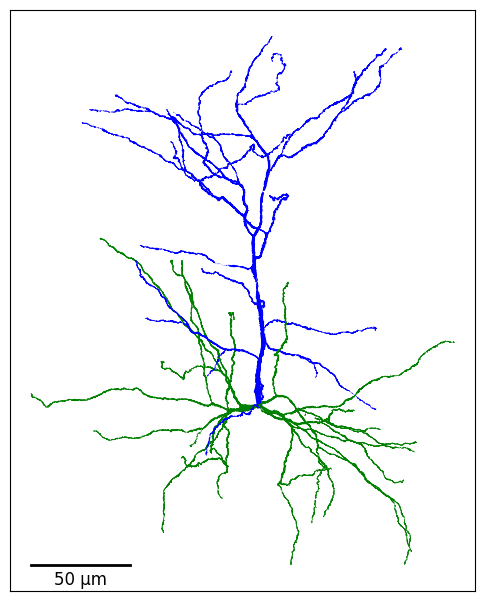

In [4]:
# draw_swc_axon(data, fig_width=6, scale=True)

In [ ]:
# draw_swc_axon(data, projection='ZY', fig_width=6, scale=True)

In [5]:
children_counts = data['parent_id'].value_counts()
data['num_children'] = data['ID'].apply(lambda x: children_counts.get(x, 0))
print(len(data))

68339


In [6]:
# Define a function to classify each point based on its appearance in 'parent_id'
def classify_point(row):
    point_id = row['ID'] # Assuming the point's ID is the index + 1 of the DataFrame
    count = row['num_children'] # Get the count, default to 0 if not in parent_id
    if count == 0:
        return 2  # Leaf (ID does not appear in any 'parent_id')
    elif count == 1:
        return 0  # Along the branch (ID appears once in 'parent_id')
    else:
        return 1  # Branch point (ID appears more than once in 'parent_id')

# Apply the function to classify each point
data['br_bf_lf'] = data.apply(classify_point, axis=1)

In [7]:
# Initialize the branch ID
branch_id = 0
branch_ids = []

for _, row in data.iterrows():
    branch_ids.append(branch_id)
    
    if row['br_bf_lf'] > 0:
        # Start a new group when 'br_br_lv' > 0
        branch_id += 1

data['branch_id'] = branch_ids
print('# branches:', branch_id)

# branches: 92


## Calculating distance of each segment from the soma

In [8]:
def distance_3d_seg(row):
    point1 = np.array([row.x, row.y, row.z])
    parent_id = row['parent_id']
    
    # Handle the root node
    if parent_id == -1:
        return 0  # Root node has no parent
    
    # Find the parent row based on parent_id
    try:
        parent_row = data.loc[data['ID'] == parent_id].iloc[0]
        point2 = np.array([parent_row.x, parent_row.y, parent_row.z])
        # Compute Euclidean distance
        return np.linalg.norm(point1 - point2)
    except IndexError:
        print(f"Warning: Parent ID {parent_id} not found for point ID {row.ID}")
        return 0

# Apply the distance calculation
data['seg_lngt'] = data.apply(distance_3d_seg, axis=1)

In [9]:
def calculate_path_to_soma(data):
    total_length_dict = {}

    # Iterate over each row in the DataFrame
    for idx, row in data.iterrows():
        current_id = row['ID']
        parent_id = row['parent_id']
        current_length = row['seg_lngt']
        parent_row = data.loc[data['ID'] == parent_id]

        # If the point has no parent (root), total length is just the current segment length
        if parent_id == -1:
            total_length_dict[current_id] = current_length
        else:
            # Total length is the parent's total length + the current segment length
            total_length_dict[current_id] = total_length_dict.get(parent_id, 0) + current_length
        
        # Assign the calculated total length to the DataFrame
        data.at[idx, 'path_to_soma'] = total_length_dict[current_id]

    return data

# Apply the function to the DataFrame
data = calculate_path_to_soma(data)


In [10]:
def indx_2_MICrONS_coordinates(indx):
    xx, yy, zz = data.iloc[indx].x, data.iloc[indx].y, data.iloc[indx].z
    return int(np.round(xx *250)),int(np.round(yy *250)),int(np.round(zz *25))


## Finding abrupt change in diameter along branches

In [11]:
def detect_multiple_abrupt_radius_changes(radii_series, drop_threshold=0.25, abs_threshold=0.25, 
                                          recovery_threshold=0.75, min_segments=1, max_segments=20,
                                          drop_search_window=20):
    """
    Detects multiple abrupt decreases in radius followed by recoveries within a limited number of segments.
    
    Parameters:
        radii_series (pd.Series): Series of radius values indexed by segment numbers.
        drop_threshold (float): Fraction of the initial radius considered an abrupt drop.
        abs_threshold (float): Minimum absolute decrease in radius.
        recovery_threshold (float): Fraction of the initial radius that must be recovered.
        min_segments (int): Minimum number of segments before checking for recovery.
        max_segments (int): Maximum number of segments allowed before recovery.
    Returns:
        list: List of tuples (drop_index, recovery_index) for each detected DSC event.
    """
    radii_values = radii_series.values  # Extract numerical values
    indices = radii_series.index        # Extract corresponding indices
    detected_events = []                # Store all detected events
    
    i = 0
    while i < len(radii_values) - min_segments:
        initial_radius = radii_values[i]  # Starting radius
        event_found = False
        
        # Look for a sharp decrease (must be a "step" drop, not gradual)
        for j in range(i + 1, np.min([i + drop_search_window + 1, len(radii_values)])):
            drop_radius = radii_values[j]
            
            # Condition 1: Ensure the drop is a sudden step, not a transition
            if radii_values[j] == radii_values[j - 1]:  
                continue  # Skip if the radius is constant
            
            # Condition 2: Drop must meet both ratio and absolute threshold conditions
            if (drop_radius < drop_threshold * initial_radius) and ((initial_radius - drop_radius) >= abs_threshold):
                drop_index = indices[j]  # Index where drop happens
                
                # Look for recovery within [min_segments, max_segments] range
                for k in range(j + min_segments, min(j + max_segments + 1, len(radii_values))):
                    
                    # Condition 3: Ensure recovery is also a sudden change
                    if radii_values[k] == radii_values[k - 1]:
                        continue  # Skip if still constant
                    
                    if radii_values[k] >= recovery_threshold * initial_radius:
                        recovery_index = indices[k]
                        detected_events.append((drop_index, recovery_index))
                        
                        # Move the starting point past this recovery to look for more events
                        i = k  # Start next search from recovery point
                        event_found = True
                        break
                
                if event_found:
                    break  # Break out of the j loop to start next search
        
        if not event_found:
            i += 1  # Move to next starting point if no event was found
    
    return detected_events


In [12]:
locs = []
coord = []   
for i in range(branch_id):
    radii_along_branch = data.loc[data['branch_id'] == i, 'radius']
    events = detect_multiple_abrupt_radius_changes(radii_along_branch, drop_threshold=0.5, abs_threshold=0.25, 
                                                   max_segments=20, drop_search_window=20)
    for drop_idx, recovery_idx in events:
        if drop_idx not in [17939,17942]: # Manual removal of visually invalid DSCs.
            print(f" Drop at: {drop_idx}, Recovery at: {recovery_idx}")
            print('branch_id:', i, indx_2_MICrONS_coordinates(drop_idx))
            coord.append( indx_2_MICrONS_coordinates(drop_idx))
            locs.append([drop_idx, recovery_idx])
        
locs = np.array(locs)

XY_DSCs = data.iloc[locs[:,0],2:4]
print(len(XY_DSCs))

DSCs_data = data.loc[XY_DSCs.index.values]


 Drop at: 6853, Recovery at: 6868
branch_id: 10 (268678, 117473, 21378)
 Drop at: 20297, Recovery at: 20312
branch_id: 31 (264882, 89501, 20954)
 Drop at: 20333, Recovery at: 20345
branch_id: 31 (264580, 89226, 20908)
 Drop at: 21283, Recovery at: 21302
branch_id: 32 (270452, 87328, 20769)
 Drop at: 23473, Recovery at: 23493
branch_id: 35 (279145, 91165, 19928)
 Drop at: 23530, Recovery at: 23542
branch_id: 35 (279558, 90642, 19860)
 Drop at: 23843, Recovery at: 23862
branch_id: 35 (280162, 90587, 19445)
 Drop at: 25437, Recovery at: 25452
branch_id: 36 (283105, 96707, 21072)
 Drop at: 31740, Recovery at: 31759
branch_id: 45 (273932, 89501, 23564)
 Drop at: 38309, Recovery at: 38329
branch_id: 53 (293530, 81236, 22700)
 Drop at: 40322, Recovery at: 40337
branch_id: 56 (296100, 80287, 22671)
 Drop at: 42689, Recovery at: 42700
branch_id: 58 (287988, 113388, 23995)
12


DSC: 25437
MICrONS coordinates:
283105 96707 21072


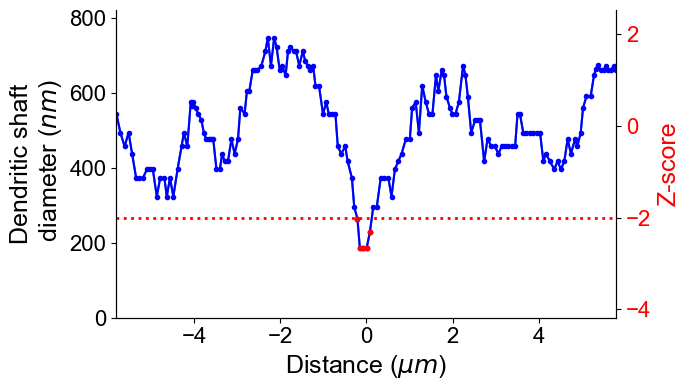

In [13]:
DSC = 25437

xx, yy, zz = data.loc[DSC].x, data.loc[DSC].y, data.loc[DSC].z
print('DSC:', DSC)
print('MICrONS coordinates:')
print(int(np.round(xx *250)),int(np.round(yy *250)),int(np.round(zz *25))) # translate to MICrONS coordinates


start, end = DSC - 80, DSC + 80
x_values = data['path_to_soma'].loc[start:end]
x_values = x_values - np.mean(x_values)

radius_values = data['radius'].loc[start:end] * 2000  # Scaled radius
zscore_values = stats.zscore(radius_values)  # Compute Z-score
mask_below_threshold = zscore_values < -2


fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(x_values, radius_values)
ax1.set_xlabel("Distance ($\mu m$)", fontsize=18, family='Arial')
ax1.set_ylabel("Dendritic shaft\n diameter ($nm$)", fontsize=18, family='Arial')

ax1.set_ylim(0, np.max(radius_values)*1.1)
ax1.set_xlim([np.min(x_values)*1.0, np.max(x_values)*1.0])
plt.gca().spines['top'].set_visible(False)
plt.xticks(family='Arial'); plt.yticks(family='Arial')
plt.tick_params(axis="x", labelsize=16); plt.tick_params(axis="y", labelsize=16)


ax2 = ax1.twinx()
ax2.plot(x_values, zscore_values, marker='.', linestyle='-', color='b', label="Z-score")
ax2.scatter(x_values[mask_below_threshold], zscore_values[mask_below_threshold], color='r', s=10, zorder=14)

ax2.set_ylabel("Z-score", color='r', fontsize=18, family='Arial')
ax2.tick_params(axis='y', labelcolor='r')
y1, y2 = ax2.get_ylim()
ax2.axhline(-2, color='r', linestyle=':', linewidth=2, label="Threshold (Z = -2)");

# Get stats of the z-score curve
z_mean = np.mean(radius_values)
z_std = np.std(radius_values)
z_min = (0 - z_mean) / z_std
z_max = (np.max(radius_values) - z_mean) / z_std
ax2.set_ylim(z_min, z_max + 0.1*(z_max-z_min))


plt.gca().spines['top'].set_visible(False)
plt.xticks(family='Arial'); plt.yticks(family='Arial')
plt.tick_params(axis="x", labelsize=16); plt.tick_params(axis="y", labelsize=16)
plt.tight_layout()


# plt.savefig(f"DSC_Dendrite_diameter_{DSC}.png", dpi=300, bbox_inches='tight')
# plt.savefig(f"DSC_Dendrite_diameter_864691135693733567_{DSC}.pdf", bbox_inches='tight')


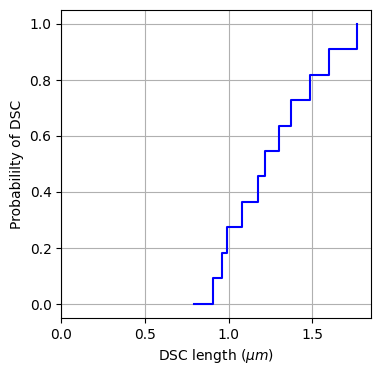

In [14]:
# calculating the length of the DSCs
DSC_lengths = []
for B in range(len(XY_DSCs)):
    DSC_length = 0
    for i in range(locs[B,0], locs[B,1]):
        DSC_length += data['seg_lngt'][i]

    DSC_lengths.append( DSC_length )

DSC_lengths_srt = np.sort(DSC_lengths)

y_values = np.linspace(0, 1, len(DSC_lengths_srt))

plt.figure(figsize=(4, 4))
plt.step(DSC_lengths_srt, y_values, where='post', color='b')
plt.xlim([0,np.max(DSC_lengths_srt)*1.05])
plt.xlabel("DSC length ($\mu m$)")
plt.ylabel("Probabililty of DSC")
plt.grid(True)
plt.show()

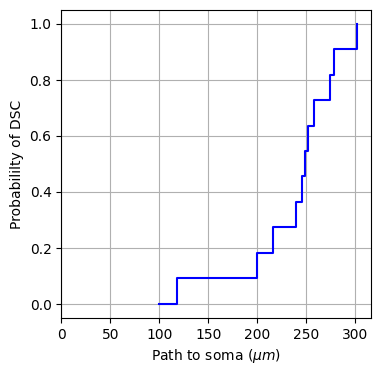

In [15]:
DSC_path_to_soma = list(DSCs_data['path_to_soma'])
DSC_path_to_soma_srt = np.sort(DSC_path_to_soma)

y_values = np.linspace(0, 1, len(DSC_path_to_soma_srt))

plt.figure(figsize=(4, 4))
plt.step(DSC_path_to_soma_srt, y_values, where='post', color='b')
plt.xlim([0,np.max(DSC_path_to_soma_srt)*1.05])
plt.xlabel("Path to soma ($\mu m$)")
plt.ylabel("Probabililty of DSC")
plt.grid(True)
plt.show()

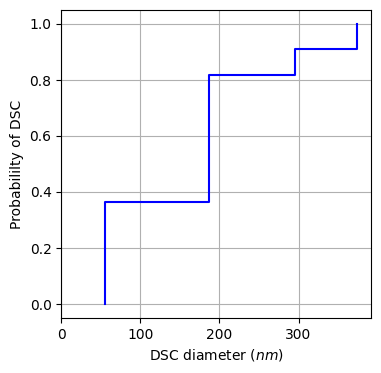

In [16]:
DSC_diam = (DSCs_data['radius'] * 2000).tolist()
DSC_diam_srt = np.sort(DSC_diam)

y_values = np.linspace(0, 1, len(DSC_diam_srt))

plt.figure(figsize=(4, 4))
plt.step(DSC_diam_srt, y_values, where='post', color='b')
plt.xlim([0,np.max(DSC_diam_srt)*1.05])
plt.xlabel("DSC diameter ($nm$)")
plt.ylabel("Probabililty of DSC")
plt.grid(True)
plt.show()

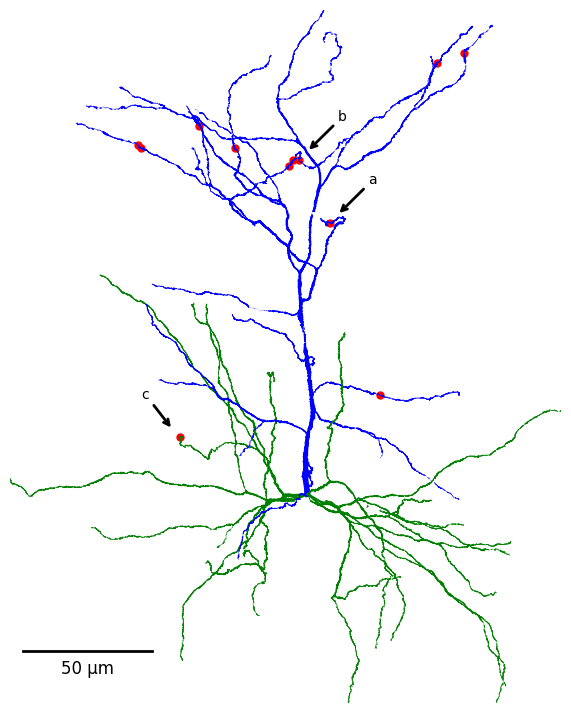

In [17]:
x_coords = []
y_coords = []
z_coords = []
radii = []
typ_s = []

for index, row in data.iterrows():
    ID, typ, x, y, z, radius, parent_id, *remaining_values = row
    if parent_id == -1:
        continue
    parent_row = data.loc[int(parent_id)-1]
    x_coords.append([x, parent_row['x']])
    y_coords.append([y, parent_row['y']])
    z_coords.append([z, parent_row['z']])
    radii.append(radius)
    typ_s.append(typ)

# Convert lists to numpy arrays for plotting
x_coords = np.array(x_coords)
y_coords = -np.array(y_coords)
z_coords = np.array(z_coords)
radii = np.array(radii)
typ_s = np.array(typ_s)

# Calculate the range for x and y
x_min, x_max = np.min(x_coords), np.max(x_coords)
y_min, y_max = np.min(y_coords), np.max(y_coords)
z_min, z_max = np.min(z_coords), np.max(z_coords)
x_range = x_max - x_min
y_range = y_max - y_min
z_range = z_max - z_min

clr = ['m', 'deepskyblue', 'r', 'g', 'b', 'pink', 'gray', 'k', 'g', 'y', 'brown']


fig_height = 9
fig_width = fig_height * (x_range / y_range)
fig = plt.figure(figsize=(fig_width, fig_height))

for i in range(len(x_coords)):
    plt.plot(x_coords[i], y_coords[i], linewidth=radii[i] * 3.0, color=clr[int(typ_s[i])])

for xx, yy in XY_DSCs.values:
    plt.scatter(xx, -yy, s=25, color='r')

# Add arrow to the DSC
first_xx, first_yy = XY_DSCs.values[7]
plt.annotate('a', xy=(first_xx + 3, -first_yy + 3), xytext=(first_xx + 15, -first_yy + 15),
             arrowprops=dict(arrowstyle='->', color='black', lw=2))

first_xx, first_yy = XY_DSCs.values[6]
plt.annotate('b', xy=(first_xx + 3, -first_yy + 3), xytext=(first_xx + 15, -first_yy + 15),
             arrowprops=dict(arrowstyle='->', color='black', lw=2))

first_xx, first_yy = XY_DSCs.values[0]
plt.annotate('c', xy=(first_xx - 3, -first_yy + 3), xytext=(first_xx - 15, -first_yy + 15),
             arrowprops=dict(arrowstyle='->', color='black', lw=2))

# Draw scale bar
scale_length = 50  # 50 µm
plt.plot([x_min+5, x_min+5 + scale_length], [y_min+20, y_min+20], 'k-', linewidth=2)
plt.text(x_min+5 + (scale_length/2), y_min+20 - (0.012 * y_range), '50 µm', fontsize=12, verticalalignment='top', horizontalalignment='center');

plt.xlim([x_min, x_max])
plt.ylim([y_min, y_max])
plt.gca().set_aspect('equal')

plt.axis('off')
plt.xticks([])
plt.yticks([]);

# plt.savefig("DSC_864691135693733567.png", dpi=900, bbox_inches='tight')
# plt.savefig("DSC_864691135693733567.eps", bbox_inches='tight')